# Super cool experiment

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geopandas import GeoDataFrame
from shapely import Polygon
from spatialdata.models import ShapesModel
from spatialdata.transformations import Identity
import numpy as np

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Import packages

In [2]:
path = "/media/sergio/ADAMEYKO_R5/xenium_datasets/Xenium_Prime_Mouse_Brain_Coronal_FF_outs"
sdata = spatialdata_io.xenium(path)

INFO     reading                                                                                                   
         /media/sergio/ADAMEYKO_R5/xenium_datasets/Xenium_Prime_Mouse_Brain_Coronal_FF_outs/cell_feature_matrix.h5 


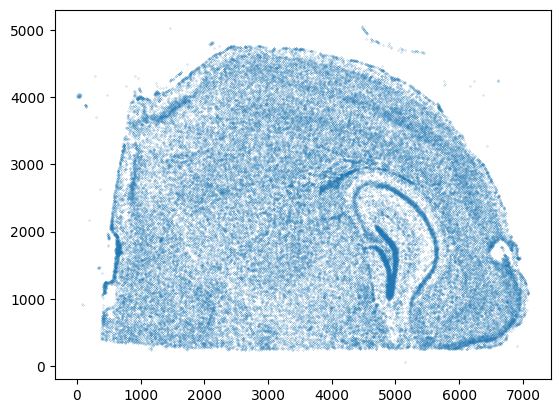

In [9]:
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.02)

In [ ]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[ 20150,2600,],
    max_coordinate=[ 28199.,13899.9,],
    target_coordinate_system="global")
cropped_sdata

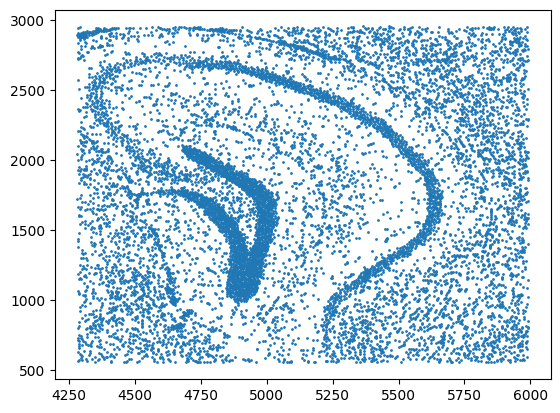

In [34]:
spat=[g[0] for g in cropped_sdata['table'].obsm['spatial']]
spat2=[g[1] for g in cropped_sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=1)

In [48]:
del cropped_sdata['nucleus_labels']

In [49]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo.zarr"
cropped_sdata.write(outpath,overwrite=True)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo.zarr                                


# Read data

In [2]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo.zarr"
sdata=sd.read_zarr(outpath)

In [30]:
trans=sdata['transcripts'].compute()
expre=pd.crosstab(trans['cell_id'],trans['feature_name'])

In [34]:
expre=expre.loc[expre.index!='UNASSIGNED',:]

In [35]:
adata=sc.AnnData(expre)

In [37]:
sdata["table"] =adata 
adata = sdata["table"]

(11128, 13073)


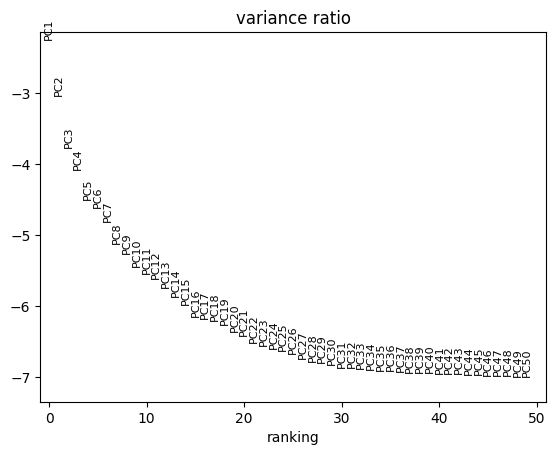

2025-04-07 15:30:07.373878: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-07 15:30:07.412807: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744032607.432029 1625972 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744032607.437141 1625972 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744032607.482773 1625972 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

(11127, 13073)


In [38]:
adata = sdata["table"]
print(adata.shape)
adata.raw = adata.copy()

sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_genes(adata, min_cells=1)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
print(adata.shape)
sc.tl.leiden(adata, key_added="leiden")

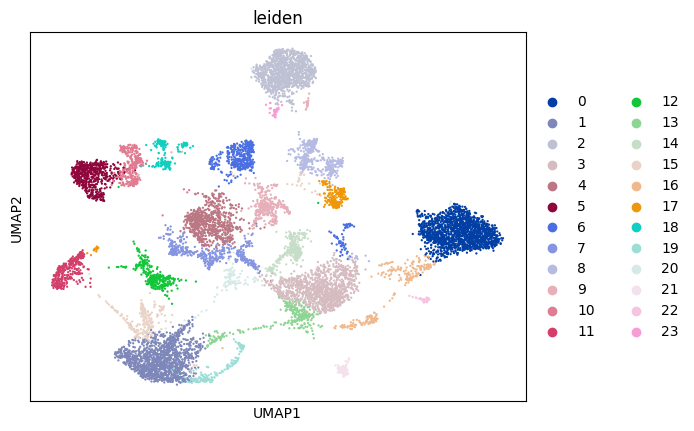

In [41]:
sc.pl.umap(adata,color='leiden')

In [46]:
sdata['table'].obs.index=sdata['table'].obs.index.astype(str)

In [49]:
outpath = "/media/sergio/wd_ssd/xenium_msbrain_5k_hippo_formatted_silvia.zarr"
sdata.write(outpath,overwrite=True)

INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/FaciltyHD12/xenium_msbrain_5k_hippo_formatted_silvia.zarr the new file path:                
         /media/sergio/wd_ssd/xenium_msbrain_5k_hippo_formatted_silvia.zarr                                        
